In [1]:
%pip install -q numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import sys, os
sys.path.insert(0, os.path.abspath('../..'))

import kalman.runtime.chrono as chrono
chrono.restart()
print('kalman imported')


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


kalman imported


# Data Assimilation — Ensemble Kalman Filtering for Fields

Every notebook so far estimated a state you could write on one line: a phasor, a trajectory, a handful of lane variables. This one estimates a **field** — the state is an entire 2D turbulent vorticity map, $n = 64\times64 = 4096$ dimensions, observed at only $p = 100$ scattered probe points.

At that scale the classical machinery collapses:

- the covariance $P$ is $n\times n$ — storing and propagating it is $O(n^2)$–$O(n^3)$;
- the dynamics are a chaotic PDE — there is no usable Jacobian $F = \partial f/\partial x$ for an EKF, and $2n{+}1$ sigma points (UKF) means $8193$ solver runs *per step*.

The **ensemble Kalman filter (EnKF)** is the standard answer, and the backbone of every operational weather/ocean data-assimilation (DA) system: represent the belief by $N \ll n$ samples ("members", here $N=16$), let the *sample* covariance stand in for $P$, and never form $P$ densely. The framework provides it as `EnsembleKalmanFilter` / `EnsembleKalmanEngine` — the same model/engine/filter contract as every other notebook.

This notebook is also the **Kalman × AI** sequel to notebook 12: the ensemble forecast step is the single most expensive part of DA ($N$ full solver runs per cycle), which makes it the natural place to insert a learned surrogate. A prototype study behind this notebook found the two ways that goes wrong — a *linear* latent space (POD/DMD) hits a hard representation floor, and a naively trained one-step surrogate diverges exponentially inside the filter — and both failure modes, with their fixes, are built into the tools used below.

**Roadmap**
1. The physical system: 2D Kolmogorov flow (chaotic Navier–Stokes).
2. The EnKF: perturbed observations, localization, inflation.
3. A twin experiment (OSSE): EnKF vs. a free-running forecast.
4. An AI forecast surrogate — trained with a rollout loss, validated open-loop *before* it touches the filter.
5. Why not a particle filter? (a live demonstration of the curse of dimensionality)
6. Imperfect-model DA: replaying an external truth — the road to ERA5.
7. Negative results worth keeping.

## 1 — The Physical System: 2D Kolmogorov Flow

The truth model is the incompressible 2D Navier–Stokes equation in vorticity form on a periodic square, with **Kolmogorov forcing** (a steady sinusoidal shear that keeps the turbulence alive):

$$
\frac{\partial \omega}{\partial t} = -\,\mathbf{u}\cdot\nabla\omega \;+\; \nu\,\nabla^2\omega \;+\; \chi\cos(k_f\, y),
\qquad \mathbf{u} = \nabla^\perp\psi,\;\; \nabla^2\psi = -\omega .
$$

`NS2D` integrates this pseudo-spectrally (FFT space, 2/3-rule dealiasing, RK4). At $\nu = 1/150$ the flow is genuinely chaotic: two nearby states separate exponentially, so an unassimilated forecast is doomed no matter how good the model is — exactly the regime where DA earns its keep.

`KolmogorovFlowModel` wraps the solver as a `KalmanModel`:

- **state** — the flattened vorticity field ($n = \text{grid}^2$); one filter step = one *assimilation cycle* (30 RK4 steps);
- **`f`** — advance the field one cycle; **`h`** — read the field at $p$ fixed probe pixels ($R = \sigma_o^2 I$);
- **`localization()`** — Gaspari–Cohn tapers on the periodic torus (Section 2);
- **`initial_ensemble(N)`** — random snapshots from a cached *climatology* run, i.e. an honest "we only know the statistics, not the state" start;
- **`forecast(X)`** — batched member propagation, and the **AI plug-in point**: assign `model.surrogate = fn` to swap the solver for a learned forecast without touching the filter.

Only the **ensemble** and **particle** engines are allowed on this model (`ALLOWED_ENGINES`) — it refuses the Jacobian-based ones by construction.

KolmogorovFlowModel(KalmanModel) @ fs=6.666666666666667Hz
    Kolmogorov Flow (v1.0)
        2D Navier–Stokes vorticity field (Kolmogorov
        forcing) with sparse point probes —
        ensemble data-assimilation testbed.
    Dimensions Summary:
        State Vector....................................: 4096 dims (KalmanState<>)
        Observation.....................................: 100 dims (FlowObservable<VORTICITY>)
        Control Input...................................: 0 dims
    Initial State:
        State Vector (x0)...............................: 4096x1 dims
        State Covariance (P0)...........................: 4096x4096 dims

state dim n = 4096, observations p = 100, field std ~ 2.50, ensemble will have N = 16 members


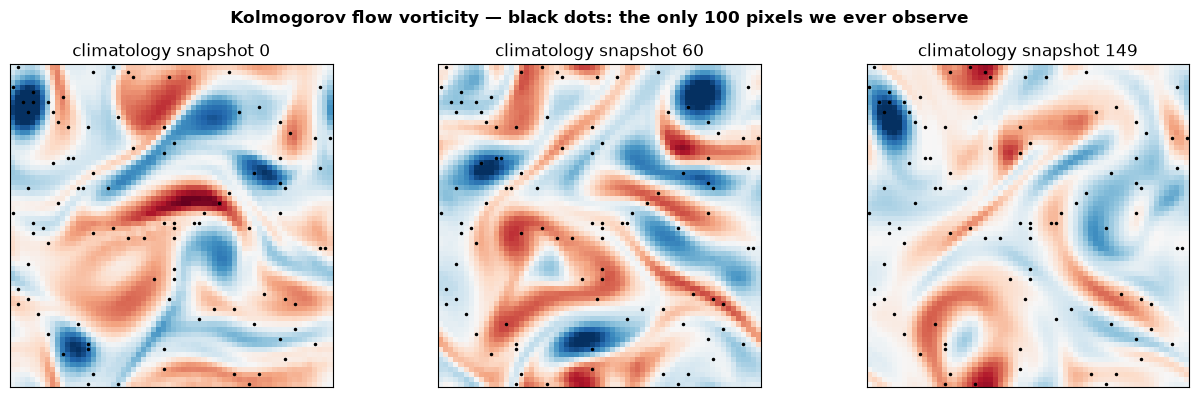

In [2]:
from kalman.apps import KolmogorovFlowModel, TwinExperiment
from kalman.framework.engines import gaspari_cohn

model = KolmogorovFlowModel("probes", grid=64, nu=1/150., chi=2.0, kf=4,
                            dt=0.005, cycle=30, n_obs=100, sig_o=0.30,
                            loc_radius=8.0, seed=7)
S = model.climatology(n_snapshots=150, spinup=2500, stride=10)   # (n, K) attractor snapshots
print(model)
print(f"state dim n = {model.n}, observations p = {model.m}, "
      f"field std ~ {S.std():.2f}, ensemble will have N = 16 members")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
oy, ox = np.divmod(model.obs_idx, model.grid)
for ax, k in zip(axes, [0, 60, 149]):
    w = S[:, k].reshape(model.grid, model.grid)
    ax.imshow(w, cmap="RdBu_r", origin="lower", vmin=-S.std()*3, vmax=S.std()*3)
    ax.plot(ox, oy, "k.", ms=3)
    ax.set_title(f"climatology snapshot {k}")
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Kolmogorov flow vorticity — black dots: the only 100 pixels we ever observe",
             fontweight="bold")
plt.tight_layout(); plt.show()

## 2 — The Ensemble Kalman Filter

One assimilation cycle, with forecast ensemble $X = [x_1,\dots,x_N]$ and anomalies $X' = X - \bar{x}$:

$$
\underbrace{PH^\top = \rho_{xy}\circ\tfrac{X'Y'^\top}{N-1}}_{\text{state–obs covariance}},\qquad
\underbrace{HPH^\top = \rho_{yy}\circ\tfrac{Y'Y'^\top}{N-1}}_{\text{obs–obs covariance}},\qquad
K = PH^\top\big(HPH^\top + R\big)^{-1},
$$

$$
x_i^a = x_i^f + K\big(y + \varepsilon_i - h(x_i^f)\big),
\qquad \varepsilon_i \sim \mathcal{N}(0, R).
$$

with $Y = h(X)$ the members mapped to observation space. Three ingredients make this work at $N=16 \ll n=4096$:

**Perturbed observations $\varepsilon_i$.** Each member is updated against its own noisy copy of the measurement. Without this the analysis ensemble collapses to too-small spread (the update would treat $y$ as exact for every member) and the filter becomes overconfident.

**Localization $\rho$.** A 16-member sample covariance between two pixels on opposite sides of the domain is pure noise, yet a naive update would let a probe "correct" pixels it carries no information about. The Gaspari–Cohn taper $\rho$ (a compactly-supported quasi-Gaussian, exactly zero beyond $2L$) multiplies the sample covariances element-wise, cutting spurious long-range correlations. The model supplies $\rho_{xy}, \rho_{yy}$ from torus distances.

**Multiplicative inflation $a$.** Anomalies are scaled by $a \gtrsim 1$ before each analysis, compensating the systematic spread underestimation of a finite ensemble (and, later, surrogate model bias). Tuned per forecast model — this matters in Section 4.

One more design decision, inherited the hard way (Section 6): the engine draws its $\varepsilon_i$ from an **engine-owned RNG stream**, never the global one, so running several filter variants side by side can never contaminate each other's randomness.

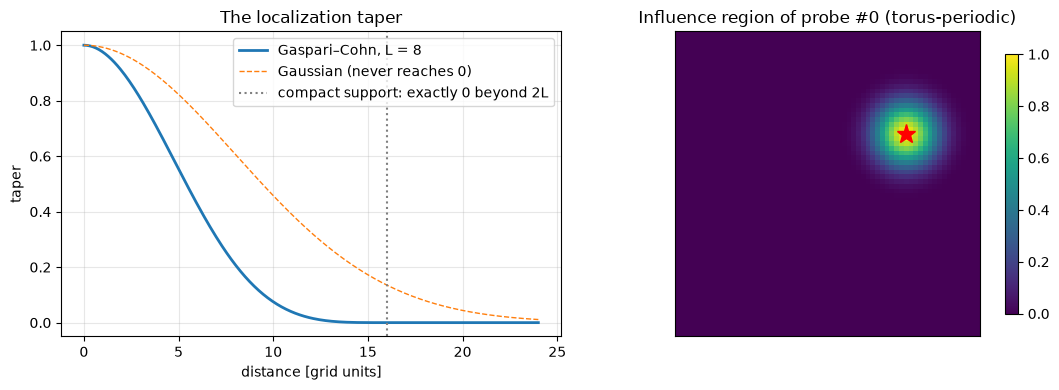

In [3]:
# The Gaspari–Cohn taper, and what localization looks like around one probe
rho_xy, rho_yy = model.localization()

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4))
d = np.linspace(0, 3 * model.loc_radius, 300)
ax0.plot(d, gaspari_cohn(d, model.loc_radius), lw=2, label=f"Gaspari–Cohn, L = {model.loc_radius:g}")
ax0.plot(d, np.exp(-0.5 * (d / model.loc_radius) ** 2), "--", lw=1, label="Gaussian (never reaches 0)")
ax0.axvline(2 * model.loc_radius, color="gray", ls=":", label="compact support: exactly 0 beyond 2L")
ax0.set_xlabel("distance [grid units]"); ax0.set_ylabel("taper")
ax0.legend(); ax0.grid(alpha=0.3); ax0.set_title("The localization taper")

im = ax1.imshow(rho_xy[:, 0].reshape(model.grid, model.grid), cmap="viridis", origin="lower")
ax1.plot(ox[0], oy[0], "r*", ms=14)
ax1.set_title("Influence region of probe #0 (torus-periodic)")
ax1.set_xticks([]); ax1.set_yticks([])
fig.colorbar(im, ax=ax1, shrink=0.85)
plt.tight_layout(); plt.show()

## 3 — Twin Experiment (OSSE): EnKF vs. Free Run

An **observing-system simulation experiment** is the standard DA validation protocol, and `TwinExperiment` packages it as the framework's harness: the truth is a real solver trajectory, observations are synthesized at the known probe locations ($y = h(x^{\text{truth}}) + \eta$, $\eta \sim \mathcal{N}(0,R)$), and every registered method assimilates *the same* observation realization from *the same* climatological initial ensemble. A `free` method (identical ensemble, never assimilates) is the control every filter must beat.

One more dose of realism: the stations are **asynchronous**. Real observation networks are neither synchronized nor equal-rate, so `obs_periods=(2, 6)` gives every probe its own reporting period — a genuinely different rate per station, from every 2nd to every 6th cycle, and **no station reports every cycle** — so the reporting subset is different each cycle and they never correct all at once; a silent station, and the silent ones contribute NaN, which the engines' **masked update** skips natively (the same NaN convention every other notebook uses for missing channels).

Because the truth and observation streams are seeded independently of the methods, results are reproducible **and** method-invariant: registering an extra method cannot change anyone else's numbers (there is a regression test for exactly this — `tests/test_ensemble.py::test_rng_discipline_invariance`).

In [4]:
N_CYCLES, N_MEMBERS = 40, 16

osse = TwinExperiment(model, n_cycles=N_CYCLES, n_members=N_MEMBERS,
                      seed_obs=999, seed_setup=123, obs_periods=(2, 6))
print(f"asynchronous network: {osse.obs_mask.sum()} station reports over "
      f"{N_CYCLES} cycles (vs {N_CYCLES * model.m} if all stations reported every cycle)")
osse.add_method("enkf", inflation=1.06)
osse.add_free_run()
hist = osse.run(every=10, record_fields=True)

clim = osse.climatological_error()
print(f"\nclimatological error (no-skill scale): {clim:.2f}")
print(f"final analysis RMSE  enkf: {hist['enkf']['rmse_a'][-1]:.3f}   "
      f"free: {hist['free']['rmse_a'][-1]:.3f}")
print(f"observation noise sigma_o = {model.sig_o}")

asynchronous network: 1109 station reports over 40 cycles (vs 4000 if all stations reported every cycle)


cycle  10: RMSE_a  enkf=1.469  free=2.373


cycle  20: RMSE_a  enkf=1.646  free=2.632


cycle  30: RMSE_a  enkf=1.692  free=2.357


cycle  40: RMSE_a  enkf=1.365  free=2.437

climatological error (no-skill scale): 3.37
final analysis RMSE  enkf: 1.365   free: 2.437
observation noise sigma_o = 0.3


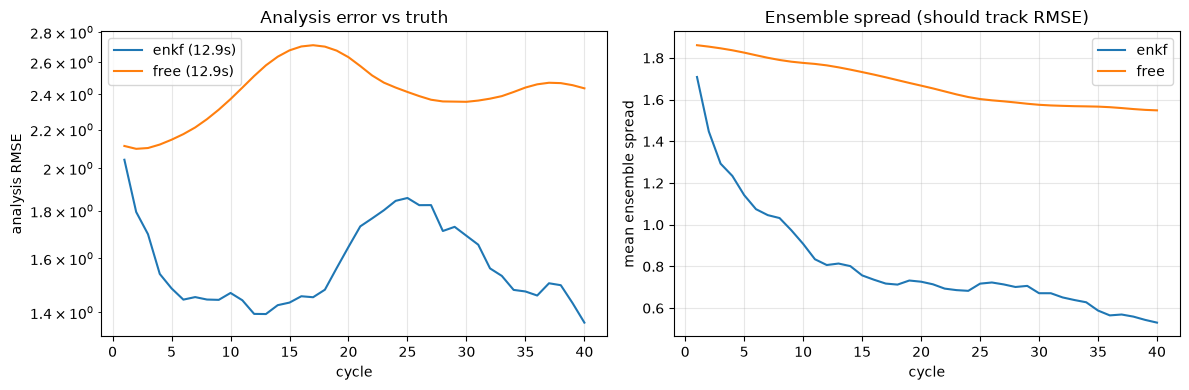

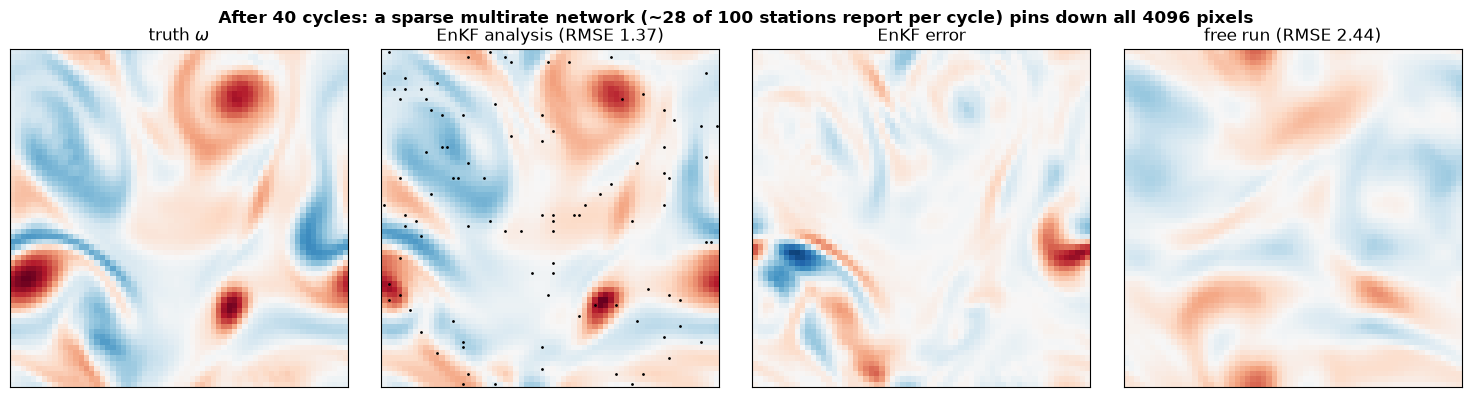

In [5]:
osse.plot()
plt.show()

# Fields at the final cycle: what the filter actually recovered from 100 pixels
enkf_mean = osse.methods["enkf"]["engine"].mean.ravel()
free_mean = osse.methods["free"]["engine"].mean.ravel()
g = model.grid
truth = osse.truth.reshape(g, g)
vmax = np.abs(truth).max()

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
panels = [(truth, "truth $\\omega$"),
          (enkf_mean.reshape(g, g), f"EnKF analysis (RMSE {hist['enkf']['rmse_a'][-1]:.2f})"),
          (enkf_mean.reshape(g, g) - truth, "EnKF error"),
          (free_mean.reshape(g, g), f"free run (RMSE {hist['free']['rmse_a'][-1]:.2f})")]
for ax, (w, title) in zip(axes, panels):
    ax.imshow(w, cmap="RdBu_r", vmin=-vmax, vmax=vmax, origin="lower")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
axes[1].plot(ox, oy, "k.", ms=2)
fig.suptitle("After 40 cycles: a sparse multirate network (~28 of 100 stations report per cycle) pins down all 4096 pixels",
             fontweight="bold")
plt.tight_layout(); plt.show()

### Watching a Measurement Arrive

The assimilation is easier to *see* than to read: below, **one frame per cycle** — the analysis field with a **black dot at exactly the stations that delivered a measurement that cycle**; idle stations are transparent. Nothing pulses: the dot pattern changes between cycles only because the asynchronous network changes who reports, each station at its own cadence, while the field converges from climatological ignorance. Scrub the slider to step through. (`animate(phases=2)` additionally plays each cycle's forecast frame — all stations idle — if you want the measurement *arrival* rendered as an explicit step.)

In [6]:
# Interactive replay -- one frame per cycle: the analysis field, with a
# black dot at each station that reported that cycle (idle = transparent).
osse.animate(method="enkf", interval=280)

Three things to read off these curves:

- **Convergence from ignorance.** The ensemble starts at climatological error (random attractor states) and the analysis error drops by an order of magnitude, toward the observation noise floor — while the free run, running *the exact same solver*, drifts at climatological error forever. On this chaotic flow that is roughly an order of magnitude of skill, all of it attributable to a sparse, multi-rate network of 100 probes — of which only ~28 report on any given cycle (each station on its own 2–6-cycle clock, so the corrected sites rotate around the map and never fire all at once). The reconstruction floor is correspondingly higher than a dense every-cycle network would give — the honest price of a realistic observing schedule.
- **Spread tracks error.** The mean ensemble spread (right panel) should approximately match the analysis RMSE — that is the ensemble's own uncertainty estimate being *calibrated*, the field-scale analogue of the NIS/NEES consistency checks from notebook 00. Spread ≪ RMSE means overconfidence (increase inflation); spread ≫ RMSE wastes information.
- **The error is structured.** The EnKF error map is small-scale and spatially uniform; the free-run field is a *different weather* entirely.

## 4 — An AI Forecast Surrogate (Kalman × AI)

The entire cost of the experiment above is the forecast step: $N$ solver runs per cycle. A learned surrogate that maps $\omega(t) \mapsto \omega(t+\text{cycle})$ in one CNN pass makes the ensemble forecast essentially free — the classic *ML-accelerated DA* proposition.

The prototype behind this notebook tried the obvious recipe first — train a small CNN on **one-step** pairs with plain MSE — and it failed in the most instructive way possible: open-loop rollout error grew rapidly, and once cycled inside the EnKF the analysis **diverged exponentially** (RMSE 3.4 → 76 over 60 cycles) while the true-solver EnKF converged on the identical setup. Nothing in a one-step objective penalizes multi-cycle drift, and the filter compounds that bias every cycle.

`kalman.apps.flowsurrogate` therefore hard-codes two non-negotiable rules for this workflow:

1. **Rollout loss** — `train_surrogate(..., rollout=k)` backpropagates through $k$ consecutive applications of the network, penalizing exactly the compounding drift the filter will feel. The architecture is a periodic-padded residual CNN predicting the *increment* $\Delta\omega$ (identity as a stable fallback).
2. **Open-loop gate** — `rollout_rmse` measures free-running surrogate error against the solver. If it approaches the climatological field std within your DA horizon, do not put it in the filter; retrain first. (Necessary, not sufficient — Section 4's results show why.)

And one budget rule from the same study: the surrogate branch gets its **own inflation** (here 1.15 vs. 1.06) — a learned model's error statistics are not the solver's.

In [7]:
try:
    from kalman.apps import flowsurrogate as fs
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False
    print("torch not installed -- skipping the surrogate section")

if HAS_TORCH:
    traj = fs.make_trajectory(model, n_cycles=200, burn=2000)     # solver snapshots, 1 cycle apart
    net, (mu, sd), val = fs.train_surrogate(traj, width=12, nblocks=2,
                                            epochs=30, rollout=4, batch=16, seed=0)
    forecast = fs.as_forecaster(net, mu, sd)
    print(f"best validation rollout-MSE (normalized): {val:.4f}")

  epoch   5: train=0.24505  val=0.20115


  epoch  10: train=0.24380  val=0.20107


  epoch  15: train=0.24035  val=0.19873


  epoch  20: train=0.23818  val=0.20055


  epoch  25: train=0.23666  val=0.19809


  epoch  30: train=0.23581  val=0.19871
best validation rollout-MSE (normalized): 0.1966


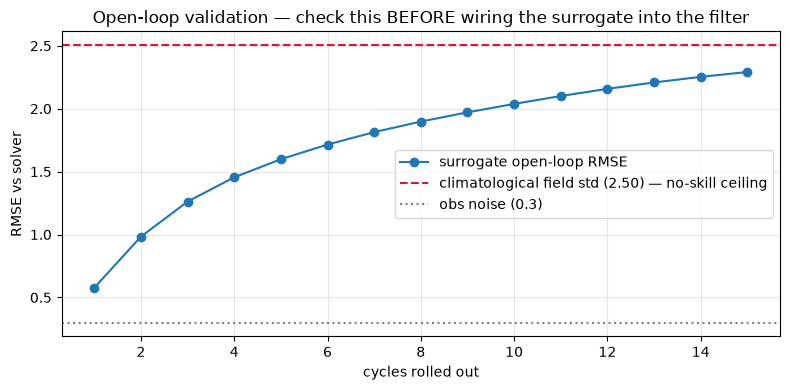

open-loop error after 15 cycles: 2.29  (climatological std 2.50)
gate verdict: FAIL — expect trouble under cycling; use a mitigation (below) or retrain


In [8]:
if HAS_TORCH:
    # The go/no-go gate: open-loop rollout error vs the true solver
    errs = fs.rollout_rmse(forecast, model, n_cycles=15)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(np.arange(1, len(errs) + 1), errs, "o-", label="surrogate open-loop RMSE")
    ax.axhline(S.std(), color="crimson", ls="--", label=f"climatological field std ({S.std():.2f}) — no-skill ceiling")
    ax.axhline(model.sig_o, color="gray", ls=":", label=f"obs noise ({model.sig_o})")
    ax.set_xlabel("cycles rolled out"); ax.set_ylabel("RMSE vs solver")
    ax.legend(); ax.grid(alpha=0.3)
    ax.set_title("Open-loop validation — check this BEFORE wiring the surrogate into the filter")
    plt.tight_layout(); plt.show()

    gate_ok = errs[-1] < 0.5 * S.std()
    print(f"open-loop error after {len(errs)} cycles: {errs[-1]:.2f}  "
          f"(climatological std {S.std():.2f})")
    print("gate verdict:", "PASS — safe to cycle" if gate_ok else
          "FAIL — expect trouble under cycling; use a mitigation (below) or retrain")

cycle  10: RMSE_a  surrogate=1.747  re-anchored=1.463


cycle  20: RMSE_a  surrogate=2.798  re-anchored=1.639


cycle  30: RMSE_a  surrogate=6.924  re-anchored=1.639


cycle  40: RMSE_a  surrogate=15.507  re-anchored=1.560


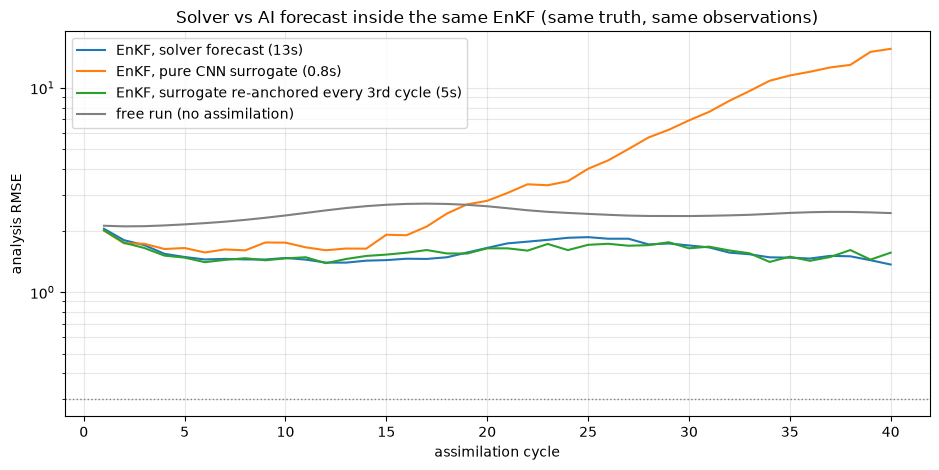

forecast+analysis wall time  enkf: 12.9s
forecast+analysis wall time  surrogate: 0.8s
forecast+analysis wall time  re-anchored: 4.8s


In [9]:
if HAS_TORCH:
    # Same truth, same observations, same initial ensemble (identical seeds) --
    # only the forecast model changes. Directly comparable to Section 3.
    # Two AI branches: the pure surrogate, and the surrogate RE-ANCHORED by the
    # true solver every 3rd cycle (the cheap mitigation for an unstable surrogate).
    hybrid = fs.ReanchoredForecast(model, forecast, every=3)
    osse2 = TwinExperiment(model, n_cycles=N_CYCLES, n_members=N_MEMBERS,
                           seed_obs=999, seed_setup=123, obs_periods=(2, 6))
    osse2.add_method("surrogate", inflation=1.15, forecast=forecast)
    osse2.add_method("re-anchored", inflation=1.10, forecast=hybrid)
    hist2 = osse2.run(every=10)

    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    cyc = np.arange(1, N_CYCLES + 1)
    ax.semilogy(cyc, hist["enkf"]["rmse_a"], label=f"EnKF, solver forecast ({hist['enkf']['time']:.0f}s)")
    ax.semilogy(cyc, hist2["surrogate"]["rmse_a"],
                label=f"EnKF, pure CNN surrogate ({hist2['surrogate']['time']:.1f}s)")
    ax.semilogy(cyc, hist2["re-anchored"]["rmse_a"],
                label=f"EnKF, surrogate re-anchored every 3rd cycle ({hist2['re-anchored']['time']:.0f}s)")
    ax.semilogy(cyc, hist["free"]["rmse_a"], label="free run (no assimilation)", color="gray")
    ax.axhline(model.sig_o, color="gray", ls=":", lw=1)
    ax.set_xlabel("assimilation cycle"); ax.set_ylabel("analysis RMSE")
    ax.legend(); ax.grid(alpha=0.3, which="both")
    ax.set_title("Solver vs AI forecast inside the same EnKF (same truth, same observations)")
    plt.tight_layout(); plt.show()
    for k in ("enkf",):
        print(f"forecast+analysis wall time  {k}: {hist[k]['time']:.1f}s")
    for k in ("surrogate", "re-anchored"):
        print(f"forecast+analysis wall time  {k}: {hist2[k]['time']:.1f}s")

This plot is the honest version of the "ML-accelerated DA" proposition, and it reproduces the prototype's central negative result *even with* rollout training at this budget:

- **The pure surrogate branch diverges.** Not because its open-loop error is catastrophic — the gate above shows it drifting to the no-skill ceiling within ~15 cycles, not exploding — but because of a feedback the open-loop test cannot see: each analysis increment nudges the field slightly **off the training manifold**, the CNN extrapolates badly there, the next analysis has to correct more, and the loop amplifies. A one-step-trained twin of this network diverged far faster (RMSE → 76 in the prototype); the rollout loss slows the spiral but a couple of CPU-minutes of training cannot eliminate it. This is why the gate verdict above must be treated as a *necessary*, not sufficient, condition.
- **Re-anchoring bounds it.** Running the true solver every 3rd cycle flushes the accumulated surrogate bias before it compounds, at roughly a third of the solver cost — and the branch stays bounded, holding a useful analysis error well below the free run for the whole experiment instead of diverging. The remaining gap to the solver-forecast branch is the surrogate's bias floor; re-anchoring is the "cheap first fix" and the baseline any extra training data or capacity must beat.
- **The escalation path**, in order of cost: longer rollout / more data / more capacity → train on *analysis-perturbed* states (close the distribution gap the filter creates) → bias correction against the solver → keep re-anchoring. All of them slot into `TwinExperiment.add_method(forecast=...)` without touching the filter.

## 5 — Why Not a Particle Filter?

The framework's `ParticleFilter` (notebook 12 used its engine for IMM-style routing) is the *other* Monte-Carlo filter, and it is strictly more general than the EnKF: no Gaussian assumption at all. So why doesn't operational DA use it?

**Weight collapse.** A bootstrap PF reweights whole trajectories by likelihood; in high dimensions one particle ends up exponentially more likely than the rest, the effective sample size collapses to 1, and the filter degenerates to a single (wrong) trajectory. The required particle count grows **exponentially** with the effective dimension — $N=4096$-dim fields are hopeless for any affordable $N$. The EnKF avoids this by *moving* every member with a linear-Gaussian update instead of *reweighting* them — trading non-Gaussian generality for dimension-robustness.

We can watch this happen on a miniature version of the same flow (16×16 grid, $n=256$), where running both through the standard `forward()` workflow is cheap: a 500-particle PF against a 16-member EnKF — the PF gets **30× more** samples and still loses.

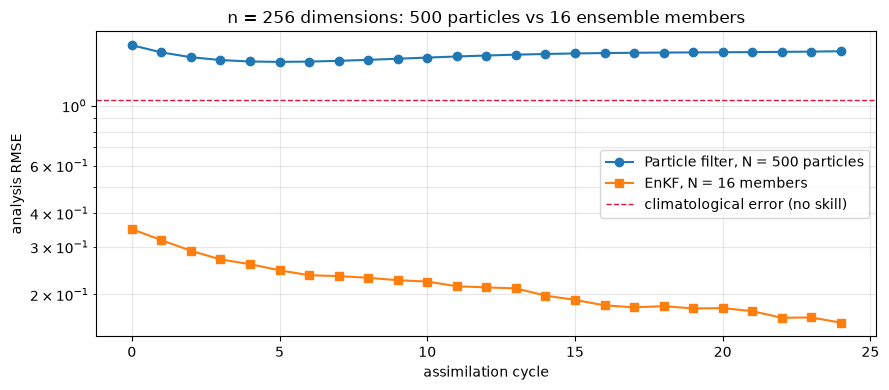

final RMSE   PF(500): 1.590   EnKF(16): 0.157


In [10]:
from kalman.filters import ParticleFilter, EnsembleKalmanFilter

mini = KolmogorovFlowModel("mini", grid=16, cycle=10, dt=0.01, nu=1/40.,
                           n_obs=40, sig_o=0.30, loc_radius=4.0, seed=7)
mini.climatology(n_snapshots=60, spinup=600, stride=5)

# truth trajectory + observations
rng_y = np.random.default_rng(21)
truth0 = mini.equilibrium_state(decorrelate=100)
truths, zs, w = [], [], truth0.copy()
for _ in range(25):
    w = mini.f(w)
    truths.append(w.copy())
    zs.append(w[mini.obs_idx] + rng_y.normal(0, mini.sig_o, mini.m))
truths, zs = np.asarray(truths), np.asarray(zs)

# both filters start from climatological uncertainty
Sm = mini.climatology()
mini.initial_state(Sm.mean(axis=1).reshape(-1, 1), float(Sm.var()) * np.eye(mini.n))

pf   = ParticleFilter(mini, n_particles=500)
enkf = EnsembleKalmanFilter(mini, n_members=16, inflation=1.05, seed=0)
rec_pf, rec_en = pf.forward(zs), enkf.forward(zs)

rmse = lambda rec: np.sqrt(np.mean((np.asarray(rec.xk) - truths) ** 2, axis=1))
fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogy(rmse(rec_pf), "o-", label="Particle filter, N = 500 particles")
ax.semilogy(rmse(rec_en), "s-", label="EnKF, N = 16 members")
ax.axhline(np.sqrt(np.mean((Sm - truths[-1][:, None]) ** 2)), color="crimson", ls="--",
           lw=1, label="climatological error (no skill)")
ax.set_xlabel("assimilation cycle"); ax.set_ylabel("analysis RMSE")
ax.legend(); ax.grid(alpha=0.3, which="both")
ax.set_title(f"n = {mini.n} dimensions: 500 particles vs 16 ensemble members")
plt.tight_layout(); plt.show()
print(f"final RMSE   PF(500): {rmse(rec_pf)[-1]:.3f}   EnKF(16): {rmse(rec_en)[-1]:.3f}")

Even at a modest $n=256$, the reweighting filter hovers near the no-skill line while 16 moved members converge. The particle filter remains the right tool where it was used in earlier notebooks — low-dimensional, strongly non-Gaussian problems — and the EnKF is the right tool for fields. (Hybrids — localized PFs, Gaussian-mixture EnKFs — are an active research area precisely because each side wants the other's strength.)

## 6 — Imperfect-Model DA: Replaying an External Truth (the Road to ERA5)

Everything above is a *perfect-model* twin: the truth evolves with the very solver the ensemble forecasts with. No real application is like that — the atmosphere is not your model. `TwinExperiment(truth_trajectory=...)` breaks that link: the truth is **replayed** from any supplied field sequence, observations are synthesized at the model's probes, and the whole harness (RMSE, spread, `skill()` ratios, RNG discipline) applies unchanged.

Here the external truth is a **nature run with half the dissipation** ($\nu = 1/300$ vs. the model's $1/150$) — the forecast model is now systematically wrong at small scales, the classic model-error setting. (`q_std` on the model adds additive model-error noise $Q$ when you want the filter to *account* for that error rather than just suffer it.)

The same three lines run against **real ERA5 reanalysis** once the optional data stack is installed (`pip install xarray netCDF4 cdsapi` + CDS credentials in `~/.cdsapirc`), via `kalman.apps.reanalysis`:

```python
from kalman.apps.reanalysis import fetch_era5, reanalysis_truth

path = fetch_era5("era5_uv500.nc", dates=("2024-08-01", "2024-08-31"),
                  area=(50, 0, 10, 360), level=500)        # N, W, S, E — a FULL zonal band
traj = reanalysis_truth(path, model, level=500, stride=1)  # u/v → ζ → regrid → model units
osse = TwinExperiment(model, truth_trajectory=traj, n_members=16)
```

Two caveats decide whether the ERA5 experiment is meaningful, and the loader enforces/documents both: use a full **zonal band** (the solver's domain is a torus — a regional box is not periodic and bleeds spurious increments at the seam), and note that `reanalysis_truth` **rescales** the sequence to the model's climatological std so that $\sigma_o$, inflation and localization keep their meaning — report results as **ratios** (`skill()`), which are invariant to that scaling.

### The Earth Canvas: Sea, Ground, and the Assimilation Band

While the CDS credentials are pending, the Earth itself is already wired in: `kalman.apps.reanalysis` ships the public-domain **Natural Earth 110m** land polygons and coastlines in-package (no cartopy), a rasterized **land–sea mask** (`land_mask` — seam-proof at any central longitude), and `plot_global_field` — the equirectangular, Pacific-centered view used by the SuperBench climate snapshot, with the continents reading through the field and the coastlines drawn on top.

The red dashed lines mark the **zonal assimilation band** (10–50°N) the model would be geo-referenced onto — a full periodic strip of longitude, matching the solver's torus. The field is a **synthetic** ERA-like wind speed (zonal jets + smooth turbulence + orographic roughness over land) standing in until the real ERA5 snapshot replaces it — same call, same canvas. (The toy model's grid probes live in the abstract Kolmogorov box, not on real coastlines, so they are deliberately *not* drawn here — real ERA5 station coordinates will be.)

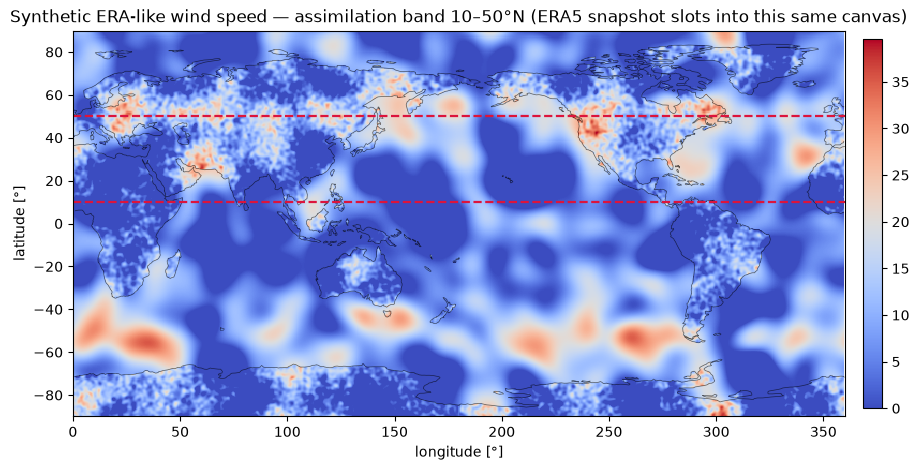

In [11]:
from kalman.apps.reanalysis import plot_global_field, land_mask

lat = np.linspace(-90, 90, 361)
lon = np.arange(0, 360, 0.5)
rng = np.random.default_rng(3)

def smooth_noise(shape, cut):
    z = rng.standard_normal(shape)
    ky = np.fft.fftfreq(shape[0])[:, None]; kx = np.fft.fftfreq(shape[1])[None, :]
    return np.real(np.fft.ifft2(np.fft.fft2(z) * np.exp(-((kx**2 + ky**2) / cut**2))))

phi = np.deg2rad(lat)[:, None]
jets = 12*np.abs(np.sin(2*phi))**3 + 6*np.exp(-((np.abs(lat[:, None]) - 55) / 8.0)**2)
turb = smooth_noise((len(lat), len(lon)), 0.02); turb = 8.0*turb/turb.std()
orog = smooth_noise((len(lat), len(lon)), 0.15)
wind = np.clip(jets + turb + 4.0*orog/orog.std()*land_mask(lat, lon), 0, None)

fig, ax = plot_global_field(wind, lat, lon, central_longitude=180, band=(10, 50),
                            title="Synthetic ERA-like wind speed — assimilation band 10–50°N "
                                  "(ERA5 snapshot slots into this same canvas)")
plt.show()

cycle  10: RMSE_a  enkf-imperfect=1.648  free=2.516


cycle  20: RMSE_a  enkf-imperfect=1.733  free=2.819


cycle  30: RMSE_a  enkf-imperfect=1.595  free=2.594


cycle  40: RMSE_a  enkf-imperfect=1.627  free=2.685


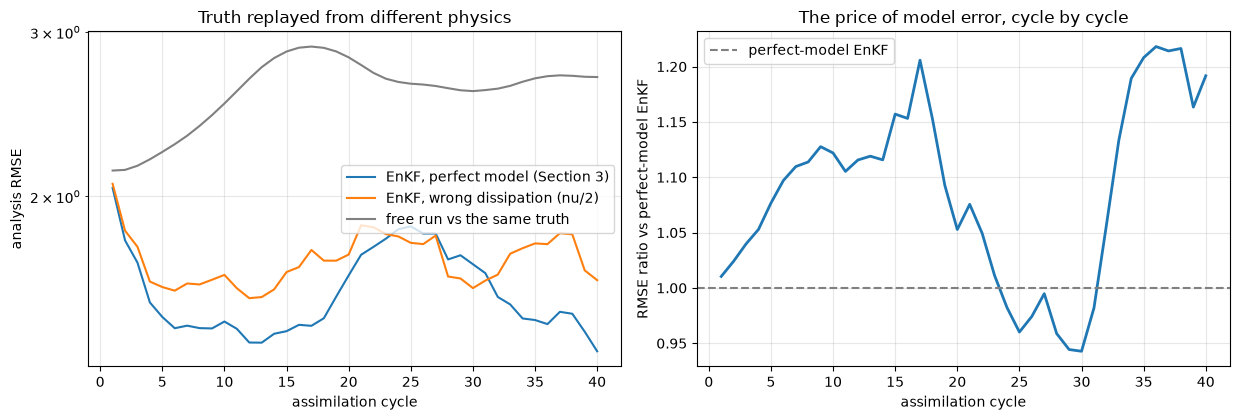

final RMSE  perfect: 1.365   imperfect: 1.627   free: 2.685   |   final ratio: 1.2x


In [12]:
nature = KolmogorovFlowModel("nature", grid=64, nu=1/300., chi=2.0, kf=4,
                             dt=0.005, cycle=30, obs_idx=model.obs_idx, seed=7)
w, traj = model.equilibrium_state(), []
for _ in range(N_CYCLES):
    w = nature.f(w)
    traj.append(w.copy())

osse3 = TwinExperiment(model, n_cycles=N_CYCLES, n_members=N_MEMBERS,
                       seed_obs=999, seed_setup=123, obs_periods=(2, 6),
                       truth_trajectory=np.asarray(traj))
osse3.add_method("enkf-imperfect", inflation=1.10)
osse3.add_free_run("free")
hist3 = osse3.run(every=10)

ratio = osse3.skill(reference=hist["enkf"])["enkf-imperfect"]   # ÷ perfect-model EnKF, per cycle
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12.5, 4.3))
cyc = np.arange(1, N_CYCLES + 1)
ax0.semilogy(cyc, hist["enkf"]["rmse_a"], label="EnKF, perfect model (Section 3)")
ax0.semilogy(cyc, hist3["enkf-imperfect"]["rmse_a"], label="EnKF, wrong dissipation (nu/2)")
ax0.semilogy(cyc, hist3["free"]["rmse_a"], color="gray", label="free run vs the same truth")
ax0.set_xlabel("assimilation cycle"); ax0.set_ylabel("analysis RMSE")
ax0.legend(); ax0.grid(alpha=0.3, which="both")
ax0.set_title("Truth replayed from different physics")
ax1.plot(cyc, ratio, lw=2)
ax1.axhline(1.0, color="gray", ls="--", label="perfect-model EnKF")
ax1.set_xlabel("assimilation cycle"); ax1.set_ylabel("RMSE ratio vs perfect-model EnKF")
ax1.legend(); ax1.grid(alpha=0.3)
ax1.set_title("The price of model error, cycle by cycle")
plt.tight_layout(); plt.show()
print(f"final RMSE  perfect: {hist['enkf']['rmse_a'][-1]:.3f}   "
      f"imperfect: {hist3['enkf-imperfect']['rmse_a'][-1]:.3f}   "
      f"free: {hist3['free']['rmse_a'][-1]:.3f}   |   final ratio: {ratio[-1]:.1f}x")

The imperfect-model branch settles at a **floor above the perfect-model curve — that gap, read off the ratio panel, *is* the model error** — while still beating the free run by a wide margin: assimilation extracts real skill even from wrong physics, which is the everyday condition of operational DA. When the replayed truth is ERA5 instead of a modified solver, this exact ratio-over-time curve becomes the honest scorecard for the toy dynamics (and for any surrogate) against the real atmosphere — the precursor experiment to a typhoon-band application.

### 6b — High-Reynolds Turbulence Datasets (Kraichnan / NSKT)

Reanalysis is not the only external truth worth replaying. Public **Kraichnan-turbulence** simulation datasets — e.g. the SuperBench *NSKT* pair: two runs at $Re = 16000$ and $Re = 32000$, $2048\times2048$ resolution, three channels ($u$, $v$, vorticity) — are in some ways an even better fit than ERA5: the domain is a **doubly-periodic box, exactly the solver's torus geometry**, so there is no seam caveat at all, and $2048/64 = 32$ makes the block-average coarse-graining exact. `kalman.apps.reanalysis` handles them directly:

```python
from kalman.apps.reanalysis import turbulence_truth

traj = turbulence_truth("nskt_re32000.h5", model, variable="vorticity", stride=4)
# or from the velocity channels: variable="uv" computes ζ spectrally
osse = TwinExperiment(model, truth_trajectory=traj, n_members=16)
```

The two Reynolds numbers invite a **cross-regime protocol**: tune the filter (or train the surrogate) against $Re=16000$, then replay $Re=32000$ as truth and read the robustness penalty straight off the `skill()` ratio.

Since the NSKT files are tens of gigabytes, the cell below runs the same protocol as a **stand-in**: a finer, more turbulent nature run ($128^2$, $\nu = 1/300$) is block-coarsened onto the $64^2$ model grid by `turbulence_truth` and replayed as truth. The model now under-resolves the truth *and* carries the wrong dissipation — the double model error a real high-$Re$ dataset will present.

The top rung teaches two things at once. First, *how* the filter is corrected matters as much as how often: the staggered multirate network — never more than a third of the stations correcting at once, each on its own clock — applies gentle, partial corrections that keep the wrong-physics model near its attractor; a hypothetical dense network correcting every site every cycle would instead keep shoving that model off its attractor, and it would re-diverge within each cycle. Second, **additive model-error noise** (`add_method(..., q_std=...)`: $Q = q_{std}^2 I$ drawn each forecast) is a knob to **tune, not a free win**: it rescued some skill in the dense-observation regime, but under the sparse staggered network the same $q_{std}=0.8$ white noise mostly pushes members further off the attractor and hurts. Closing the remaining gap to the perfect-model curve needs a better forecast model — which is exactly what this rung of the ladder is telling you.

cycle  10: RMSE_a  enkf-hires=2.366  enkf-hires+Q=2.534  free=2.949


cycle  20: RMSE_a  enkf-hires=1.858  enkf-hires+Q=2.276  free=2.850


cycle  30: RMSE_a  enkf-hires=1.436  enkf-hires+Q=1.881  free=2.870


cycle  40: RMSE_a  enkf-hires=1.622  enkf-hires+Q=1.718  free=2.908


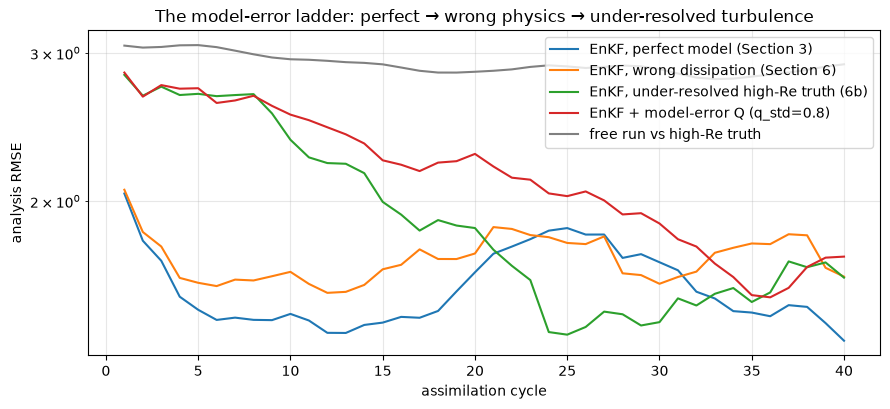

final RMSE  enkf-hires: 1.622   +Q: 1.718   free: 2.908   |   ratio vs perfect-model EnKF: 1.2x


In [13]:
from kalman.apps.reanalysis import turbulence_truth
from kalman.apps import NS2D

hires = NS2D(n=128, nu=1/300., kf=4, chi=2.0, dt=0.005, seed=11)
w = hires.advance(hires.random_ic(), 2500)                  # independent spin-up
frames = []
for _ in range(N_CYCLES):
    w = hires.advance(w, 30)
    frames.append(w.copy())
traj_hr = turbulence_truth(np.asarray(frames), model)       # 128² -> block-mean -> 64², rescaled

osse4 = TwinExperiment(model, n_cycles=N_CYCLES, n_members=N_MEMBERS,
                       seed_obs=999, seed_setup=123, obs_periods=(2, 6),
                       truth_trajectory=traj_hr)
osse4.add_method("enkf-hires", inflation=1.12)
osse4.add_method("enkf-hires+Q", inflation=1.05, q_std=0.8)   # additive model-error noise
osse4.add_free_run("free")
hist4 = osse4.run(every=10)
ratio4 = osse4.skill(reference=hist["enkf"])["enkf-hires"]

fig, ax = plt.subplots(figsize=(9, 4.2))
cyc = np.arange(1, N_CYCLES + 1)
ax.semilogy(cyc, hist["enkf"]["rmse_a"], label="EnKF, perfect model (Section 3)")
ax.semilogy(cyc, hist3["enkf-imperfect"]["rmse_a"], label="EnKF, wrong dissipation (Section 6)")
ax.semilogy(cyc, hist4["enkf-hires"]["rmse_a"], label="EnKF, under-resolved high-Re truth (6b)")
ax.semilogy(cyc, hist4["enkf-hires+Q"]["rmse_a"], label="EnKF + model-error Q (q_std=0.8)")
ax.semilogy(cyc, hist4["free"]["rmse_a"], color="gray", label="free run vs high-Re truth")
ax.set_xlabel("assimilation cycle"); ax.set_ylabel("analysis RMSE")
ax.legend(); ax.grid(alpha=0.3, which="both")
ax.set_title("The model-error ladder: perfect → wrong physics → under-resolved turbulence")
plt.tight_layout(); plt.show()
print(f"final RMSE  enkf-hires: {hist4['enkf-hires']['rmse_a'][-1]:.3f}   "
      f"+Q: {hist4['enkf-hires+Q']['rmse_a'][-1]:.3f}   "
      f"free: {hist4['free']['rmse_a'][-1]:.3f}   |   ratio vs perfect-model EnKF: {ratio4[-1]:.1f}x")

## 7 — Negative Results Worth Keeping

The prototype study that produced this notebook spent most of its budget on things that *didn't* work. They are recorded here because each one shapes the API you just used.

**Linear latent-space DA (POD/DMD) has a hard floor — that's why there is no `latent=` option.** A 50-mode POD basis captured 99.5% of *time-averaged energy* on this flow, yet instantaneous turbulent snapshots kept an RMS component of ~0.95 (field std ~2) orthogonal to even the full snapshot span. Energy capture is a second-moment, time-averaged statistic; it says nothing about representing *individual* states. Consequence: an EnKF whose analysis lives in any linear latent space stalled at RMSE ≈ 1.2 regardless of latent dimension (15–150 tested) or tuning — barely better than no assimilation. Two extra traps for whoever revisits this: inflating in *full* space pumps the unobservable orthogonal residual and can end up **worse than no assimilation**; and even latent-only inflation needs the orthogonal residual explicitly damped or it grows without bound. If a latent space is ever needed (learned observation operators, genuine reduction), it must be a **nonlinear autoencoder**, validated on instantaneous-snapshot reconstruction error — not energy capture — before it touches a filter.

**Surrogate forecasts diverge under cycling far more easily than open-loop tests suggest.** The prototype's one-step-trained net exploded (RMSE 3.4 → 76); Section 4 shows a rollout-trained net at toy budget still spirals, because the *analysis increments push states off the training manifold* — a distributional failure no open-loop metric sees. The rollout loss, the `rollout_rmse` gate, and `ReanchoredForecast` all exist because of this.

**Shared RNG streams silently invalidate comparisons.** An early version of the prototype drew *everything* from one global stream. Merely adding a second method to the loop consumed extra draws and changed the observation noise every other method saw — method A's "own" results moved from RMSE 0.19 to 1.6 with A's code untouched. The discipline now baked into the framework: one shared stream for the physical observation realization (`TwinExperiment.rng_obs` — every method must see the same measurements), one **engine-owned** stream per method for perturbed-obs draws (`EnsembleKalmanEngine(seed=...)`). `test_rng_discipline_invariance` pins this forever.

## Summary

| | |
|---|---|
| **Estimate fields, not vectors** | `EnsembleKalmanFilter` — sample covariance from $N\ll n$ members, never a dense $P$; perturbed observations keep the spread honest |
| **Make $N=16$ work in $n=4096$** | Gaspari–Cohn localization (`model.localization()`) kills spurious long-range sample covariances; multiplicative inflation compensates finite-$N$ overconfidence |
| **Validate like the weather services** | `TwinExperiment` (OSSE): known truth, synthetic obs, free-run control, RMSE *and* spread-vs-error calibration |
| **Insert AI where it pays** | the forecast step (`model.surrogate` / `add_method(forecast=...)`): train with a **rollout loss**, gate on **open-loop rollout error**, give the surrogate branch its **own inflation**, and **re-anchor** with the true solver until it earns full trust |
| **Replay any truth** | `TwinExperiment(truth_trajectory=...)`: imperfect-model twins and real-data (ERA5) experiments in the same harness; `kalman.apps.reanalysis` turns u/v reanalysis into a model-units trajectory; judge by `skill()` ratios |
| **Don't** | analyse in a linear latent space (representation floor); trust one-step training under cycling; share RNG streams across compared methods; use a bootstrap PF on fields |

The pattern to carry to a real application (regional weather, typhoon tracks, plasma profiles): keep the full-space localized EnKF as the analysis backbone, treat every learned component as a *forecast* or *observation* plug-in behind the same model contract, and make it earn its place inside this harness first.